# pp 能损比较：当前幂律注入与历史单能结果

**当前计算为总能量 10 GeV–10 PeV 的 E^-1 注入，分析和唯一能谱图在文末。前面保留历史 1 TeV 单能结果，不能与新数据直接混合统计。**

# 连续 pp 能损与 PYTHIA 传播结果比较

读取 `pion_loss_pythia_t1e8.csv`，对应 `pion_loss_pythia.cpp` 当前模型：1000 个初始动能 1000 GeV 的质子，$n_H=1$ cm$^{-3}$，传播 $10^8$ yr。使用 $v=c$、同一个外部 pp 非弹性截面，无空间输运或逃逸。

连续模型积分 $dT/dt=-0.5\Gamma(T)T$；PYTHIA 模型抽样碰撞时间，每次只保留最高能末态质子。**此数据尚未启用中子 β 衰变再生**，不是后来 power-law 程序中“衰变完成后的最高能质子”模型。低于 1 GeV 后停止碰撞。

`proton_present=0` 时 `T_pythia_GeV=0` 是分支终止的记账值，不是真实零动能质子。所有能谱图排除该类记录；其比例单独报告。CSV 没有保存传播时间、密度等元数据，下面参数来自对应的 C++ 设置，换数据时应同步核对。

In [21]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

file = Path('pion_loss_pythia_t1e8.csv')
if not file.exists():
    file = Path('output/pion_loss_pythia_t1e8.csv')
nH = 1.0                 # cm^-3
T_end = 1e8               # yr
kappa = 0.5
T_model_min = 1.0         # GeV
c_cm_s = 2.99792458e10
yr2s = 31557600.0


## 读取与分支分类

每行对应一个初始粒子。连续模型列是该粒子的确定性预测；PYTHIA 列是其保留分支的最终动能。只追踪一个质子分支，不能把结果解释为全部次级质子的能谱。

In [22]:
# Named CSV columns keep energies and branch flags explicit.
data = np.genfromtxt(file, delimiter=',', names=True)
particle_id = data['particle_id'].astype(int)
T_initial = data['T_initial_GeV']
T_continuous = data['T_continuous_GeV']
T_pythia = data['T_pythia_GeV']
N_collisions = data['N_collisions'].astype(int)
proton_present = data['proton_present'].astype(int)
has_proton = proton_present == 1
uncollided = N_collisions == 0
terminated = ~has_proton
N_particles = len(data)
N_surviving = np.sum(has_proton)

assert np.all(np.isfinite(T_pythia))
assert np.all((proton_present == 0) | (proton_present == 1))
assert np.all(T_pythia[terminated] == 0)
assert np.all(T_pythia[has_proton] > 0)
assert np.allclose(T_pythia[uncollided], T_initial[uncollided])
assert np.all(has_proton[uncollided])
assert np.allclose(T_initial, T_initial[0])
assert np.allclose(T_continuous, T_continuous[0])
print('Injected particles:', N_particles)
print('Initial kinetic energy [GeV]:', T_initial[0])
print('Continuous final kinetic energy [GeV]:', T_continuous[0])
print('Surviving proton branches:', N_surviving)
print('Terminated branches:', np.sum(terminated))
print('Uncollided particles:', np.sum(uncollided))

Injected particles: 1000
Initial kinetic energy [GeV]: 1000.0
Continuous final kinetic energy [GeV]: 205.4416200266202
Surviving proton branches: 776
Terminated branches: 224
Uncollided particles: 31


## 平均动能与分支比例

含终止分支零值的均值 $\sum T/N_{\rm initial}$ 表示每个初始粒子对应的保留质子分支动能；条件均值 $\sum T/N_{\rm surviving}$ 仅针对仍有质子的分支。前者与连续值的差异还包含分支终止影响。误差是有限样本标准误，不包括模型误差。

In [23]:
mean_per_injected = np.mean(T_pythia)
mean_surviving = np.mean(T_pythia[has_proton])
error_per_injected = np.std(T_pythia, ddof=1) / np.sqrt(N_particles)
error_surviving = np.std(T_pythia[has_proton], ddof=1) / np.sqrt(N_surviving)
p_surviving = N_surviving / N_particles
p_uncollided = np.sum(uncollided) / N_particles
print('Retained energy per injected particle [GeV]:', mean_per_injected, '+/-', error_per_injected)
print('Mean energy conditional on surviving proton [GeV]:', mean_surviving, '+/-', error_surviving)
print('Surviving fraction:', p_surviving)
print('Terminated fraction:', 1 - p_surviving)
print('Mean collisions per injected particle:', np.mean(N_collisions))
print('Relative difference of retained mean from continuous:', mean_per_injected / T_continuous[0] - 1)
print('Relative difference of conditional mean from continuous:', mean_surviving / T_continuous[0] - 1)

Retained energy per injected particle [GeV]: 90.37207448793284 +/- 7.318978429132007
Mean energy conditional on surviving proton [GeV]: 116.45885887620211 +/- 9.222912953281526
Surviving fraction: 0.776
Terminated fraction: 0.22399999999999998
Mean collisions per injected particle: 2.199
Relative difference of retained mean from continuous: -0.5601082464389502
Relative difference of conditional mean from continuous: -0.43312918355534824


末态能谱统一在文末绘制；不再单独绘制均值、累积分布或碰撞次数图。

所有谱使用实验室系总能量 $E=T+m_p$，而 CSV 中保存的是动能。

## 碰撞次数与无碰撞概率

初次碰撞前能量不变，因此无碰撞概率的解析值为
$$P_0=\exp[-n_Hc\sigma(T_0)t].$$
整个碰撞次数分布不一定是泊松分布：每次碰撞后能量和碰撞率改变，分支也可能终止。

In [24]:
T0 = T_initial[0]
T_threshold = 0.2797
L = np.log(T0 / T_threshold)
sigma0 = (30.7 - 0.96 * L + 0.18 * L**2) * (1 - (T_threshold / T0)**1.9)**3 * 1e-27
rate0 = nH * c_cm_s * sigma0 * yr2s
p0_theory = np.exp(-rate0 * T_end)
p0_error = np.sqrt(p0_theory * (1 - p0_theory) / N_particles)
print('Uncollided fraction: simulation =', p_uncollided, ', theory =', p0_theory)
print('Expected sampling standard error:', p0_error)

Uncollided fraction: simulation = 0.031 , theory = 0.03683453901607102
Expected sampling standard error: 0.005956320655534301


## 解释范围

连续模型采用固定非弹性度 0.5，PYTHIA 每次给出随机末态；二者比较还包含核子筛选、无质子分支终止及能量相关碰撞率的影响。现有数据不能分离这些效应。

特别是中子携带的能量未通过 β 衰变重新计入，本结果不能解释为完整核子输运，也不能与后来启用全部强子衰变的 `pp_powerlaw_spectrum.cpp` 结果直接等同。后续若修改生成程序，应重新生成 CSV 并执行本 notebook。

## 新模型：全部可衰变强子衰变后选择最高能质子

`pion_loss_pythia_decays.cpp` 使用相同的初始动能、粒子数、气体密度、传播时间、外部截面和 1 GeV 截止。每次碰撞后，启用所有具有衰变表的强子衰变，包括中子 β 衰变，再选最高能质子继续传播。衰变在质心系完成，再变换到固定靶实验室系。

采用瞬时衰变近似：衰变飞行时间不计入传播时钟，不处理衰变前的再碰撞。反质子不作为候选。每次仍只保留一个领先质子，不是全部次级核子的分支输运。

原数据使用默认衰变设置并在无质子时终止；新数据包括质子再生。两者是**整体模型比较**，不是逐事件配对比较：衰变消耗随机数，路径和后续碰撞次数改变，且生成参考系不同。相同种子不代表相同粒子编号拥有同一次反应历史。前面各节保留原结果，以下使用统一分箱并列比较。

In [25]:
file_decays = file.parent / 'pion_loss_pythia_decays_t1e8.csv'
data_decays = np.genfromtxt(file_decays, delimiter=',', names=True)
T_decays = data_decays['T_pythia_GeV']
has_proton_decays = data_decays['proton_present'].astype(int) == 1
N_collisions_decays = data_decays['N_collisions'].astype(int)
N_from_neutron = data_decays['N_leading_from_neutron'].astype(int)
N_decays = len(data_decays)
assert N_decays == N_particles
assert np.array_equal(data_decays['particle_id'], data['particle_id'])
assert np.allclose(data_decays['T_initial_GeV'], T_initial)
assert np.allclose(data_decays['T_continuous_GeV'], T_continuous)
assert np.all(np.isfinite(T_decays))
assert np.all(T_decays[~has_proton_decays] == 0)
assert np.all(T_decays[has_proton_decays] > 0)
assert np.allclose(T_decays[N_collisions_decays == 0], T_initial[N_collisions_decays == 0])
assert np.all(N_from_neutron <= N_collisions_decays)

cases = ['Default decays', 'All hadron decays']
energies = [T_pythia, T_decays]
presence = [has_proton, has_proton_decays]
collision_numbers = [N_collisions, N_collisions_decays]
means = []
errors = []
survival = []
for label, T_values, present, collisions in zip(cases, energies, presence, collision_numbers):
    mean = np.mean(T_values)
    error = np.std(T_values, ddof=1) / np.sqrt(len(T_values))
    means.append(mean)
    errors.append(error)
    survival.append(np.mean(present))
    print(label)
    print('  Retained kinetic energy per injected particle [GeV]:', mean, '+/-', error)
    print('  Conditional mean for surviving protons [GeV]:', np.mean(T_values[present]))
    print('  Survival fraction:', np.mean(present))
    print('  Mean number of collisions:', np.mean(collisions))
    print('  Uncollided fraction:', np.mean(collisions == 0))
print('Continuous energy [GeV]:', T_continuous[0])
print('Selected neutron-decay daughters across all collisions:', np.sum(N_from_neutron))
print('Fraction of trajectories selecting a neutron-decay daughter at least once:', np.mean(N_from_neutron > 0))

Default decays
  Retained kinetic energy per injected particle [GeV]: 90.37207448793284 +/- 7.318978429132007
  Conditional mean for surviving protons [GeV]: 116.45885887620211
  Survival fraction: 0.776
  Mean number of collisions: 2.199
  Uncollided fraction: 0.031
All hadron decays
  Retained kinetic energy per injected particle [GeV]: 131.19928421535215 +/- 7.553027274609962
  Conditional mean for surviving protons [GeV]: 131.19928421535215
  Survival fraction: 1.0
  Mean number of collisions: 3.156
  Uncollided fraction: 0.032
Continuous energy [GeV]: 205.4416200266202
Selected neutron-decay daughters across all collisions: 1155
Fraction of trajectories selecting a neutron-decay daughter at least once: 0.707


## 注入与末态的 $dN/d\ln E$

同一图中比较注入、连续能损末态、原 PYTHIA 末态和完整强子衰变后的 PYTHIA 末态。纵轴为计数除以 $\Delta\ln E$，没有除以初始粒子数；对 $d\ln E$ 积分得到各谱的粒子数。原 PYTHIA 的终止分支不计入能谱，因此其积分为 776，其余三条为 1000。单能峰的高度取决于分箱宽度。

单能历史结果保留数值统计；当前幂律注入的能谱图见文末。

新模型中高能中子可以先衰变为质子，再成为继续传播的领先粒子，因此不再直接丢弃这一部分能量。它同时改变后续碰撞率、碰撞次数和分支终止概率，不能把两组均值之差简单解释为中子 β 衰变释放的能量。连续模型仍固定采用 kappa=0.5；新模型与连续模型的差异包含真实随机末态、领先粒子筛选和非弹性度模型差别。

## 当前模型：$dN/dE\propto E^{-1}$，10 GeV–10 PeV

读取 `pion_loss_pythia_powerlaw_t1e8.csv`。$E$ 为实验室系总能量，抽样后转换为动能 $T=E-m_p$。每个初始粒子分别计算连续能损和随机传播，均为 $n_H=1$ cm$^{-3}$、$10^8$ yr、$v=c$ 和相同外部截面；连续模型采用 $\kappa=0.5$。

PYTHIA 每次碰撞完成全部可用强子衰变，再选择最高能末态质子继续传播。衰变在质心系计算，之后变换到固定靶实验室系；衰变时间近似为零。不追踪其他质子分支或反质子。两种模型仍沿用 1 GeV 动能截止。

传播时通过指数等待时间决定是否碰撞，**不是所有粒子都被强制碰撞一次**。以下只画注入、连续模型末态和完整衰变 PYTHIA 末态的 $dN/d\ln E$。

In [26]:
file_powerlaw = file.parent / 'pion_loss_pythia_powerlaw_t1e8.csv'
data_powerlaw = np.genfromtxt(file_powerlaw, delimiter=',', names=True)
m_p = 0.93827  # GeV, PYTHIA proton mass
E_injection_powerlaw = data_powerlaw['T_initial_GeV'] + m_p
E_continuous_powerlaw = data_powerlaw['T_continuous_GeV'] + m_p
present_powerlaw = data_powerlaw['proton_present'].astype(int) == 1
E_pythia_powerlaw = data_powerlaw['T_pythia_GeV'][present_powerlaw] + m_p
N_powerlaw = len(data_powerlaw)
assert np.all((E_injection_powerlaw >= 10) & (E_injection_powerlaw <= 1e7))
assert np.all(np.isfinite(data_powerlaw['T_pythia_GeV']))
assert np.all(data_powerlaw['T_pythia_GeV'][~present_powerlaw] == 0)
assert np.all(data_powerlaw['T_continuous_GeV'] <= data_powerlaw['T_initial_GeV'])
uncollided_powerlaw = data_powerlaw['N_collisions'] == 0
assert np.allclose(data_powerlaw['T_pythia_GeV'][uncollided_powerlaw],
                   data_powerlaw['T_initial_GeV'][uncollided_powerlaw])
print('Injected particles:', N_powerlaw)
print('Proton survival fraction:', np.mean(present_powerlaw))
print('Uncollided fraction:', np.mean(uncollided_powerlaw))
print('Mean initial kinetic energy [GeV]:', np.mean(data_powerlaw['T_initial_GeV']))
print('Mean continuous final kinetic energy [GeV]:', np.mean(data_powerlaw['T_continuous_GeV']))
print('Retained PYTHIA energy per injected particle [GeV]:', np.mean(data_powerlaw['T_pythia_GeV']))

Injected particles: 10000
Proton survival fraction: 1.0
Uncollided fraction: 0.0252
Mean initial kinetic energy [GeV]: 711434.2814553515
Mean continuous final kinetic energy [GeV]: 48784.23637587614
Retained PYTHIA energy per injected particle [GeV]: 20872.585818520813


In [27]:
file_powerlaw_t1e9 = file.parent / 'pion_loss_pythia_powerlaw_t1e9.csv'
data_powerlaw_t1e9 = np.genfromtxt(file_powerlaw_t1e9, delimiter=',', names=True)
assert len(data_powerlaw_t1e9) == N_powerlaw
assert np.array_equal(data_powerlaw_t1e9['particle_id'], data_powerlaw['particle_id'])
assert np.array_equal(data_powerlaw_t1e9['T_initial_GeV'], data_powerlaw['T_initial_GeV'])
present_t1e9 = data_powerlaw_t1e9['proton_present'].astype(int) == 1
E_continuous_t1e9 = data_powerlaw_t1e9['T_continuous_GeV'] + m_p
E_pythia_t1e9 = data_powerlaw_t1e9['T_pythia_GeV'][present_t1e9] + m_p
assert np.all(np.isfinite(E_pythia_t1e9))
assert np.all(data_powerlaw_t1e9['T_continuous_GeV'] <= data_powerlaw['T_continuous_GeV'] + 1e-8)
print('1e9 yr proton survival fraction:', np.mean(present_t1e9))
print('1e9 yr continuous mean kinetic energy [GeV]:', np.mean(data_powerlaw_t1e9['T_continuous_GeV']))
print('1e9 yr PYTHIA retained mean kinetic energy [GeV]:', np.mean(data_powerlaw_t1e9['T_pythia_GeV']))

1e9 yr proton survival fraction: 1.0
1e9 yr continuous mean kinetic energy [GeV]: 1.0
1e9 yr PYTHIA retained mean kinetic energy [GeV]: 0.6918107005400103


### 加入 $10^9$ 年传播

两个时间使用完全相同的初始能量样本，分别运行独立传播。相同粒子编号不代表同一条随机碰撞轨迹的两个快照。两种时间都使用相同的外部碰撞率、完整强子衰变和最高能质子筛选。

连续积分在 1 GeV 动能截止处停止，避免有限步长越过截止。随机模型最后一次碰撞仍可降到 1 GeV 以下。$10^9$ 年结果的低能堆积会明显受到这个人为截止影响，不能视为真实低能谱预测。

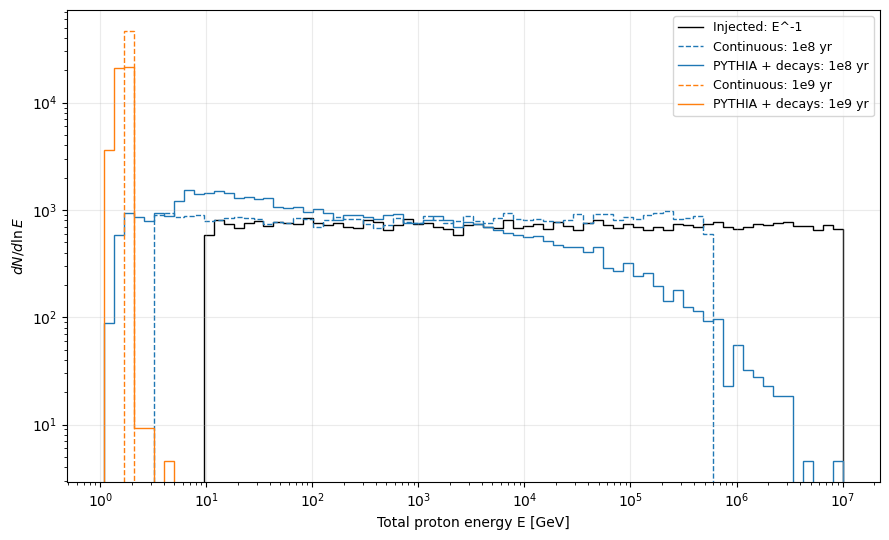

In [28]:
# Shared bins and count normalization for both propagation times.
E_min_plot = min(np.min(E_pythia_powerlaw), np.min(E_continuous_powerlaw),
                 np.min(E_pythia_t1e9), np.min(E_continuous_t1e9)) * 0.99
bins_powerlaw = np.logspace(np.log10(E_min_plot), np.log10(1e7 * 1.01), 75)
dlogE_powerlaw = np.log(bins_powerlaw[1:] / bins_powerlaw[:-1])
fig, ax = plt.subplots(figsize=(9, 5.5))
spectra = [
    (E_injection_powerlaw, 'Injected: E^-1', 'black', '-'),
    (E_continuous_powerlaw, 'Continuous: 1e8 yr', 'C0', '--'),
    (E_pythia_powerlaw, 'PYTHIA + decays: 1e8 yr', 'C0', '-'),
    (E_continuous_t1e9, 'Continuous: 1e9 yr', 'C1', '--'),
    (E_pythia_t1e9, 'PYTHIA + decays: 1e9 yr', 'C1', '-'),
]
for energies, label, color, style in spectra:
    counts, edges = np.histogram(energies, bins=bins_powerlaw)
    assert np.sum(counts) == len(energies)
    spectrum = counts / dlogE_powerlaw
    assert np.isclose(np.sum(spectrum * dlogE_powerlaw), len(energies))
    ax.stairs(spectrum, edges, label=label, color=color, linestyle=style)
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel('Total proton energy E [GeV]')
ax.set_ylabel(r'$dN/d\ln E$')
ax.legend(fontsize=9)
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(file.parent / 'pion_loss_pythia_powerlaw_comparison.png', dpi=180)
plt.show()

所有谱使用同一组分箱，纵轴是计数除以 $\Delta\ln E$，没有除以初始粒子数。图对 $d\ln E$ 的积分分别为初始粒子数、连续末态粒子数、PYTHIA 保留分支数。原先 1 TeV 单能曲线不混入本图。图中高能端差异及低能堆积反映整个传播模型，不能只归因于中子 β 衰变的微小能量损失。